# 01 — Exploration des données (Phase 1)
Objectif : comprendre la structure et la qualité de CIC-DDoS2019 avant tout traitement.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from ddos_tl.config import load_config, resolve

CONFIG = "configs/default.yaml"   # utiliser "configs/synthetic.yaml" pour un test rapide
cfg = load_config(CONFIG)
LABEL = cfg["data"]["label_column"]

In [2]:
from ddos_tl.data.loading import read_csv_dir
raw = read_csv_dir(resolve(cfg["paths"]["target_raw"]), cfg["data"].get("sample_frac_per_file"), cfg["seed"])
print(raw.shape)
raw.head()

(431371, 81)


,Unnamed: 0,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Class,_file
0,0,17,216631,6,0,2088.0,0.0,393.0,321.0,348.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UDP,Attack,cicddos2019_dataset
1,1,17,2,2,0,802.0,0.0,401.0,401.0,401.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UDP,Attack,cicddos2019_dataset
2,2,17,48,2,0,766.0,0.0,383.0,383.0,383.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UDP,Attack,cicddos2019_dataset
3,3,17,107319,4,0,1398.0,0.0,369.0,330.0,349.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UDP,Attack,cicddos2019_dataset
4,4,17,107271,4,0,1438.0,0.0,389.0,330.0,359.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UDP,Attack,cicddos2019_dataset


## Types, valeurs manquantes, infinis, doublons

In [3]:
feats = [c for c in raw.columns if c not in (LABEL, "_file")]
num = raw[feats].apply(pd.to_numeric, errors="coerce")
report = pd.DataFrame({
    "dtype": raw[feats].dtypes.astype(str),
    "missing": num.isna().sum(),
    "inf": np.isinf(num).sum(),
    "constant": num.nunique(dropna=True) <= 1,
})
# doublons calculés APRÈS retrait des colonnes d'identification (sinon un index unique masque les doublons)
no_id = raw.drop(columns=[c for c in cfg["data"]["drop_columns"] if c in raw.columns])
print("Doublons :", no_id.drop(columns=["_file"]).duplicated().sum(), "/", len(raw))
report[(report.missing > 0) | (report.inf > 0) | report.constant | (report.dtype == "object")]

Doublons : 5449 / 431371


,dtype,missing,inf,constant
Bwd PSH Flags,int64,0,0,True
Fwd URG Flags,int64,0,0,True
Bwd URG Flags,int64,0,0,True
FIN Flag Count,int64,0,0,True
PSH Flag Count,int64,0,0,True
ECE Flag Count,int64,0,0,True
Fwd Avg Bytes/Bulk,int64,0,0,True
Fwd Avg Packets/Bulk,int64,0,0,True
Fwd Avg Bulk Rate,int64,0,0,True
Bwd Avg Bytes/Bulk,int64,0,0,True


## Colonnes d'identification (risque de *shortcut learning*)
Vérifie ici lesquelles existent dans TES fichiers et complète `data.drop_columns` dans la config.

In [4]:
print([c for c in raw.columns if any(k in c.lower() for k in ("ip", "id", "time", "port", "unnamed", "simillar"))])

['Unnamed: 0', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']


## Distribution des classes (déséquilibre ?)

Label
DrDoS_NTP        121368
TFTP              98917
Benign            97831
Syn               49373
UDP               18090
DrDoS_UDP         10420
UDP-lag            8872
MSSQL              8523
DrDoS_MSSQL        6212
DrDoS_DNS          3669
DrDoS_SNMP         2717
LDAP               1906
DrDoS_LDAP         1440
Portmap             685
NetBIOS             644
DrDoS_NetBIOS       598
UDPLag               55
WebDDoS              51
Name: count, dtype: int64

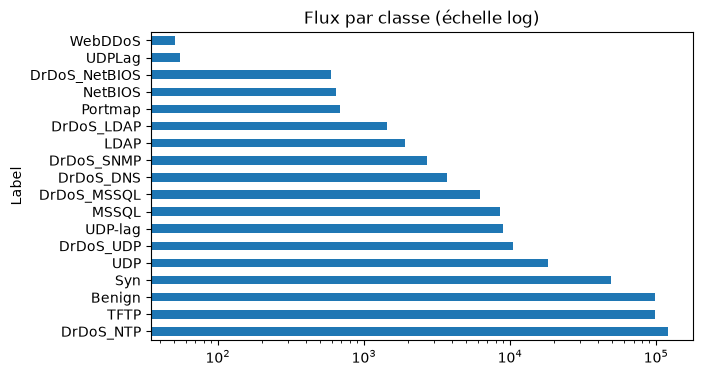

Label,Benign,DrDoS_DNS,DrDoS_LDAP,DrDoS_MSSQL,DrDoS_NTP,DrDoS_NetBIOS,DrDoS_SNMP,DrDoS_UDP,LDAP,MSSQL,NetBIOS,Portmap,Syn,TFTP,UDP,UDP-lag,UDPLag,WebDDoS
_file,,,,,,,,,,,,,,,,,,
cicddos2019_dataset,97831,3669,1440,6212,121368,598,2717,10420,1906,8523,644,685,49373,98917,18090,8872,55,51


In [5]:
counts = raw[LABEL].astype(str).str.strip().value_counts()
display(counts)
counts.plot.barh(logx=True, figsize=(7, 4), title="Flux par classe (échelle log)"); plt.show()
# Répartition des classes par fichier : utile pour décider d'un split par fichier / par jour
pd.crosstab(raw["_file"], raw[LABEL].astype(str).str.strip())

## Corrélations (échantillon)

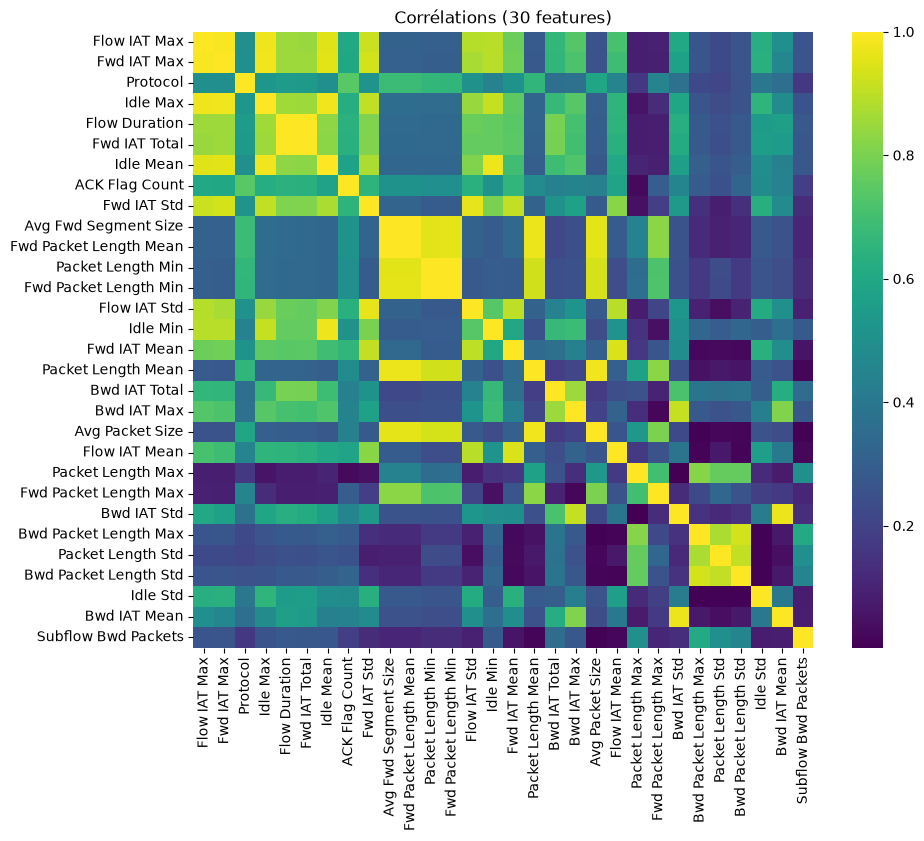

In [6]:
sample = num.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how="all").sample(min(20000, len(num)), random_state=0)
corr = sample.corr().abs()
top = corr.mean().sort_values(ascending=False).index[:30]
plt.figure(figsize=(10, 8)); sns.heatmap(corr.loc[top, top], cmap="viridis"); plt.title("Corrélations (30 features)"); plt.show()

## Décisions à noter dans le rapport
- Colonnes retirées et pourquoi
- Stratégie d'échantillonnage (`max_rows_per_class`, `sample_frac_per_file`)
- Mode de split (`random` ou `by_file`) et justification
- Classes rares retirées (`min_rows_per_class`)